# Industrial Machine Failure Prediction

## Problem Statement

The objective of this project is to predict whether an industrial machine is likely to fail based on its operating conditions.

The project uses machine operating parameters such as machine type, air temperature, process temperature, rotational speed, torque, and tool wear.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

## 1. Load Dataset

In [14]:
df = pd.read_csv("../data/ai4i2020.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Data Inspection

In [15]:
print(df.info())
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

## 3. Data Cleaning

UDI and Product ID are identifier columns, so they are removed from the predictive features.

In [16]:
df = df.drop_duplicates()

df = df.drop(
    columns=["UDI", "Product ID"],
    errors="ignore"
)

df.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 4. Target Distribution

Machine failure
0    9661
1     339
Name: count, dtype: int64
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


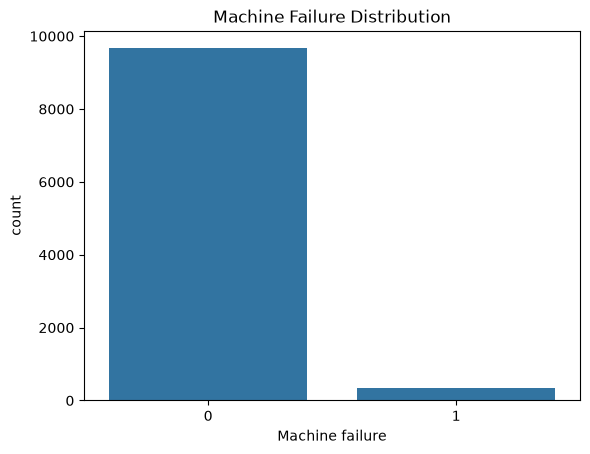

In [17]:
print(df["Machine failure"].value_counts())

print(
    df["Machine failure"]
    .value_counts(normalize=True) * 100
)

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.show()

## 5. Exploratory Data Analysis

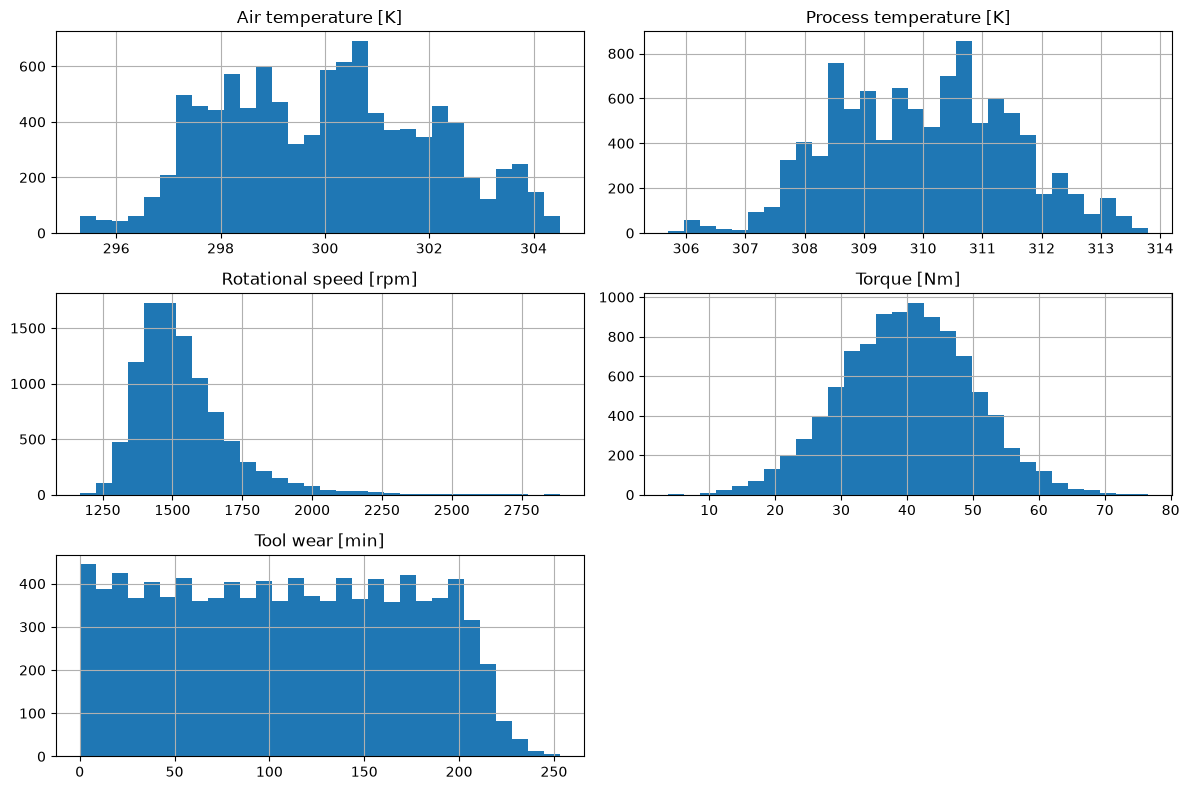

In [18]:
numeric_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numeric_columns].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

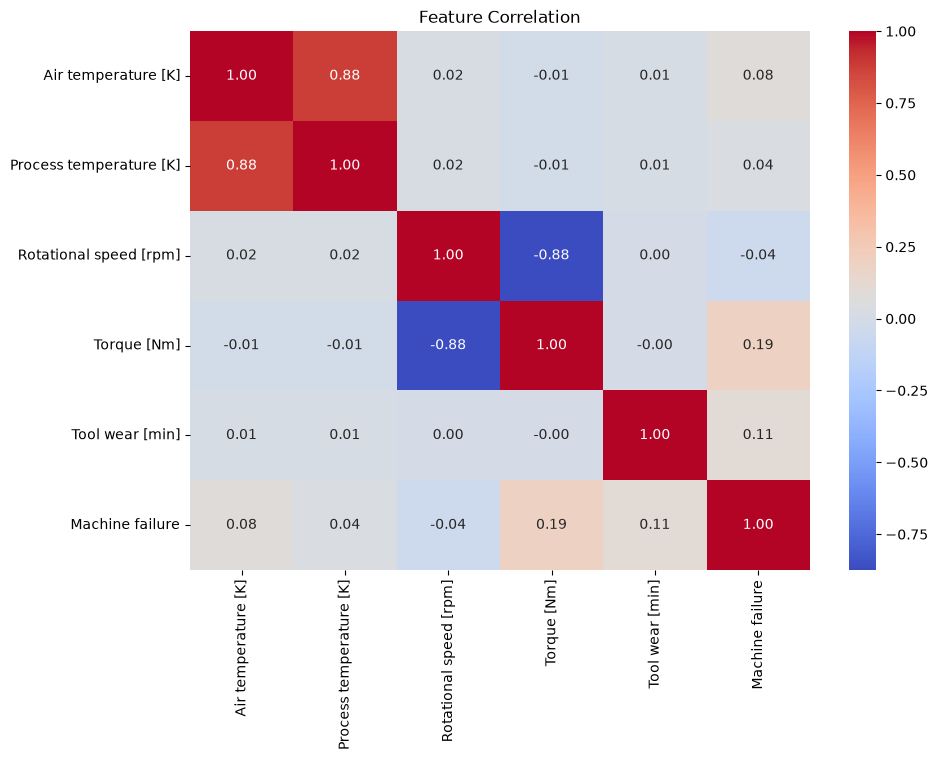

In [19]:
plt.figure(figsize=(10, 7))

correlation = df[
    numeric_columns + ["Machine failure"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation")
plt.show()

## 6. Feature Selection

Selected features:

- Type
- Air temperature [K]
- Process temperature [K]
- Rotational speed [rpm]
- Torque [Nm]
- Tool wear [min]

Target:

- Machine failure

In [20]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"

X = df[features]
y = df[target]

## 7. Train/Test Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8000, 6)
Testing: (2000, 6)


## 8. Preprocessing

Numerical features are standardized using StandardScaler.

The categorical Type feature is converted into numerical representation using OneHotEncoder.

In [22]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

## 9. Model Training

Three classification models are trained:

1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors (KNN)

In [23]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessing", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessing", preprocessor),
        ("model", DecisionTreeClassifier(
            random_state=42,
            class_weight="balanced"
        ))
    ]),

    "KNN": Pipeline([
        ("preprocessing", preprocessor),
        ("model", KNeighborsClassifier(
            n_neighbors=5
        ))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
KNN trained successfully


## 10. Model Evaluation

In [24]:
results = []

for name, model in models.items():

    prediction = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test,
            prediction,
            zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            probability
        )
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8245,0.141772,0.823529,0.241901,0.906954
1,Decision Tree,0.9790,0.732143,0.602941,0.661290,0.797589
2,KNN,0.9740,0.833333,0.294118,0.434783,0.829086


## 11. Model Comparison

The models are compared using Accuracy, Precision, Recall, F1 Score and ROC-AUC.

Because the dataset is imbalanced, multiple evaluation metrics are considered rather than accuracy alone.

## 12. Final Model

Based on the F1 score used in the training pipeline, the Decision Tree model was selected as the final model.

The trained model was saved as:

models/best_model.pkl

## 13. Conclusion

The project demonstrates an end-to-end machine-learning workflow for industrial machine failure prediction.

The workflow includes data preprocessing, exploratory data analysis, feature selection, model training, model evaluation, model comparison and deployment through a Streamlit application.

The final trained model is integrated into the Streamlit application to provide machine failure predictions from user-provided operating conditions.